# 강판 표면 결함 분류 - Baseline 모델

과제 요구사항의 **"필수 전처리만 적용한 Baseline을 만들고 네 모델의 성능을 비교"** 단계입니다.

- 모델: Logistic Regression / Decision Tree / Random Forest / GradientBoostingClassifier (모두 기본 설정)
- 불균형 처리 없음: class_weight, 샘플링, 튜닝, 앙상블, 확률 보정 모두 적용하지 않음
- 분할: Train 60 / Validation 20 / Test 20 층화 분할, 분할 인덱스를 저장해 이후 실험에서 그대로 재사용
- 평가: Macro F1 주지표 + Accuracy, Balanced Accuracy, 등급별 Precision·Recall·F1, 혼동행렬

이후 실험(가중치만 / RUS만 / SMOTE만 / 튜닝)은 저장된 분할과 결과 CSV를 불러와 이 Baseline과 비교합니다.

In [1]:
# ============================================================
# 0. 라이브러리 및 설정
# ============================================================

import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_val_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"

VAL_SIZE = 0.20
TEST_SIZE = 0.20
RUN_REPEATED_CV = True     # 학습+검증 데이터 반복 층화 5-Fold × 3 (안정성 확인용)

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
TARGET = "Fault_Type"
CAT_COLS = ["Steel_Type"]


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=FAULT_COLS, average="macro", zero_division=0)


def score_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, labels=FAULT_COLS,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, labels=FAULT_COLS,
                                     average="macro", zero_division=0),
        "Macro F1": macro_f1(y_true, y_pred),
    }


def boot_ci(y_true, y_pred, n=1000, seed=RANDOM_STATE):
    """테스트셋 재표본 Macro F1의 95% 구간 (테스트셋 구성에 따른 흔들림)"""
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    s = [macro_f1(y_true[b], y_pred[b])
         for b in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(s, [2.5, 97.5])

In [2]:
# ============================================================
# 1. 데이터 불러오기 및 정답 열 검증
# ============================================================

raw_df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", raw_df.shape)

for cols, label in [(STEEL_COLS, "강종"), (FAULT_COLS, "결함 유형")]:
    missing = [c for c in cols if c not in raw_df.columns]
    if missing:
        raise ValueError(f"{label} 열이 없습니다: {missing}")
    if not raw_df[cols].isin([0, 1]).all().all():
        raise ValueError(f"{label} 열은 0 또는 1이어야 합니다.")
    if not (raw_df[cols].sum(axis=1) == 1).all():
        raise ValueError(f"{label}이(가) 정확히 하나로 정해지지 않는 행이 있습니다.")
print("검증 통과: 강종 2열, 결함 7열 모두 0/1 이며 행 합계 1")


def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type(범주형), 결함 7열 → Fault_Type(단일 라벨)"""
    out = data.copy()
    if set(STEEL_COLS).issubset(out.columns):
        pos = out.columns.get_loc("TypeOfSteel_A300")
        steel = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(pos, "Steel_Type", steel)
    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)
    return out


df = merge_columns(raw_df)

# 누수 제외 목록: 정답을 직접 담고 있는 열은 입력에서 모두 제외
LEAKAGE_COLS = FAULT_COLS + [TARGET]
X_all = df.drop(columns=[TARGET])
y_all = df[TARGET].to_numpy()
assert not set(LEAKAGE_COLS) & set(X_all.columns), "정답 열이 입력에 남아 있습니다."

NUM_COLS = [c for c in X_all.columns if c not in CAT_COLS]
print(f"분석 대상: {df.shape[0]}행 / 입력 변수 {X_all.shape[1]}개 "
      f"(수치형 {len(NUM_COLS)}, 범주형 {len(CAT_COLS)}) / 타깃 1개")
print("누수 제외 열:", FAULT_COLS)
print("병합된 열   :", STEEL_COLS, "→ Steel_Type")

원본 데이터 크기: (1941, 34)
검증 통과: 강종 2열, 결함 7열 모두 0/1 이며 행 합계 1
분석 대상: 1941행 / 입력 변수 26개 (수치형 25, 범주형 1) / 타깃 1개
누수 제외 열: ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
병합된 열   : ['TypeOfSteel_A300', 'TypeOfSteel_A400'] → Steel_Type


결측치 합계: 0
전체 행 중복: 0 / 입력값 기준 중복: 0

[수치형 변수 요약 - 이상치 후보 비율 높은 순]


,dtype,고유값 수,최소,중앙값,최대,IQR 이상치 비율(%)
Sum_of_Luminosity,int64,1909,250.000,19202.000,1.159141e+07,20.556
Pixels_Areas,int64,920,2.000,174.000,1.526550e+05,20.350
Outside_X_Index,float64,454,0.002,0.010,8.760000e-01,19.062
X_Perimeter,int64,399,2.000,26.000,1.044900e+04,18.135
Steel_Plate_Thickness,int64,24,40.000,70.000,3.000000e+02,12.365
Y_Perimeter,int64,317,1.000,25.000,1.815200e+04,9.222
Maximum_of_Luminosity,int64,100,37.000,127.000,2.530000e+02,7.522
Luminosity_Index,float64,1522,-0.999,-0.133,6.420000e-01,6.904
Y_Minimum,int64,1939,6712.000,1204128.000,1.298766e+07,4.173
Y_Maximum,int64,1940,6724.000,1204136.000,1.298769e+07,4.173



[결함 유형 분포]


,건수,비율(%)
Other_Faults,673,34.67
Bumps,402,20.71
K_Scatch,391,20.14
Z_Scratch,190,9.79
Pastry,158,8.14
Stains,72,3.71
Dirtiness,55,2.83


최대 / 최소 클래스 비율: 12.24배


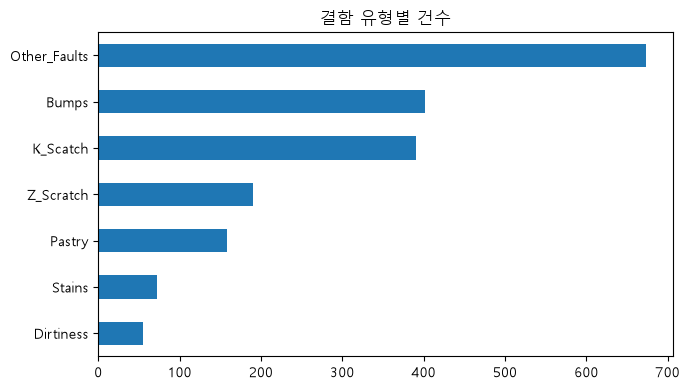


[결함 유형 × 강종]


Steel_Type,A300,A400
Fault_Type,,
Pastry,49,109
Z_Scratch,172,18
K_Scatch,1,390
Stains,1,71
Dirtiness,9,46
Bumps,279,123
Other_Faults,266,407


Chi2 = 667.0, df = 6, p = <0.001, Cramér's V = 0.586


In [3]:
# ============================================================
# 2. 데이터 구조 점검 (결측, 중복, 이상치 후보, 클래스 분포)
# ============================================================

print("결측치 합계:", df.isna().sum().sum())
print("전체 행 중복:", raw_df.duplicated().sum(),
      "/ 입력값 기준 중복:", X_all.duplicated().sum())

# 이상치 후보: IQR 1.5배 밖 비율 (삭제하지 않고 확인만 함)
q1, q3 = X_all[NUM_COLS].quantile(0.25), X_all[NUM_COLS].quantile(0.75)
iqr = q3 - q1
outlier_rate = ((X_all[NUM_COLS] < q1 - 1.5 * iqr) |
                (X_all[NUM_COLS] > q3 + 1.5 * iqr)).mean()

struct_df = pd.DataFrame({
    "dtype": X_all[NUM_COLS].dtypes.astype(str),
    "고유값 수": X_all[NUM_COLS].nunique(),
    "최소": X_all[NUM_COLS].min(),
    "중앙값": X_all[NUM_COLS].median(),
    "최대": X_all[NUM_COLS].max(),
    "IQR 이상치 비율(%)": outlier_rate * 100,
}).sort_values("IQR 이상치 비율(%)", ascending=False)
print("\n[수치형 변수 요약 - 이상치 후보 비율 높은 순]")
display(struct_df.round(3))

class_df = pd.DataFrame({"건수": pd.Series(y_all).value_counts()}).reindex(FAULT_COLS)
class_df["비율(%)"] = class_df["건수"] / class_df["건수"].sum() * 100
print("\n[결함 유형 분포]")
display(class_df.sort_values("건수", ascending=False).round(2))
print(f"최대 / 최소 클래스 비율: {class_df['건수'].max() / class_df['건수'].min():.2f}배")

ax = class_df["건수"].sort_values().plot.barh(figsize=(7, 4))
ax.set_title("결함 유형별 건수")
plt.tight_layout()
plt.show()


# 강종 - 결함 유형 관계
ct = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
print("\n[결함 유형 × 강종]")
display(ct)
print(f"Chi2 = {chi2:.1f}, df = {dof}, p = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cramers_v:.3f}")

In [4]:
# ============================================================
# 3. Train / Validation / Test 층화 분할 (60 / 20 / 20)
# ============================================================
# 테스트 20%를 먼저 떼고, 남은 80%를 75 : 25로 나눈다.
# 분할 인덱스를 저장해 이후 모든 실험(가중치, 샘플링, 튜닝)에서 같은 분할을 쓴다.
# ============================================================

idx_trval, idx_test = train_test_split(
    np.arange(len(df)), test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE
)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=y_all[idx_trval], random_state=RANDOM_STATE
)

X_train, X_val, X_test = X_all.iloc[idx_train], X_all.iloc[idx_val], X_all.iloc[idx_test]
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

split_dist = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts(),
    "Val": pd.Series(y_val).value_counts(),
    "Test": pd.Series(y_test).value_counts(),
}).reindex(FAULT_COLS)
split_dist.loc["합계"] = split_dist.sum()
print(f"Train {len(idx_train)} / Val {len(idx_val)} / Test {len(idx_test)}")
display(split_dist)

joblib.dump({"train": idx_train, "val": idx_val, "test": idx_test,
             "random_state": RANDOM_STATE}, "split_indices.joblib")
print("분할 인덱스 저장: split_indices.joblib")

Train 1164 / Val 388 / Test 389


,Train,Val,Test
Pastry,94,32,32
Z_Scratch,114,38,38
K_Scatch,235,78,78
Stains,43,15,14
Dirtiness,33,11,11
Bumps,241,80,81
Other_Faults,404,134,135
합계,1164,388,389


분할 인덱스 저장: split_indices.joblib


In [5]:
# ============================================================
# 4. 필수 전처리 + Baseline 모델 정의
# ============================================================
# 전처리는 Pipeline 안에 넣어 Train 데이터로만 fit 되도록 한다 (검증·테스트 누수 방지).
#   - 수치형: 중앙값 결측 대체 (+ 로지스틱 회귀만 표준화)
#   - 범주형(Steel_Type): 최빈값 결측 대체 + 원핫 인코딩
# 현재 데이터에는 결측이 없지만, 새 데이터에 결측이 생겨도 동작하도록 포함한다.
# 모든 모델은 기본 하이퍼파라미터, class_weight 없음.
# ============================================================

def make_preprocessor(scale: bool) -> ColumnTransformer:
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [("impute", SimpleImputer(strategy="most_frequent")),
                 ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_COLS),
        ("cat", Pipeline(cat_steps), CAT_COLS),
    ])


LR_MAX_ITER = 1000

BASELINE = {
    # 이름: (모델, 표준화 여부)
    "Logistic Regression": (LogisticRegression(max_iter=LR_MAX_ITER,
                                               random_state=RANDOM_STATE), True),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
}


def make_pipeline(name: str) -> Pipeline:
    model, scale = BASELINE[name]
    return Pipeline([("prep", make_preprocessor(scale)), ("model", model)])


for name in BASELINE:
    print(f"{name:<20} 표준화: {BASELINE[name][1]}")

Logistic Regression  표준화: True
Decision Tree        표준화: False
Random Forest        표준화: False
Gradient Boosting    표준화: False


In [6]:
# ============================================================
# 5. 학습 및 평가 (Train으로 학습 → Train / Val / Test 점수)
# ============================================================
# 로지스틱 회귀는 수렴 경고와 반복 횟수를 함께 기록한다.
# ============================================================

fitted = {}
score_rows = []
fit_info = []

for name in BASELINE:
    pipe = make_pipeline(name)
    start = time.time()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        pipe.fit(X_train, y_train)
    elapsed = time.time() - start
    conv_warn = any(issubclass(x.category, ConvergenceWarning) for x in w)

    model = pipe.named_steps["model"]
    if hasattr(model, "n_iter_"):
        n_iter = int(np.max(model.n_iter_))
        converged = (n_iter < LR_MAX_ITER) and not conv_warn
        conv_text = f"{'수렴' if converged else '미수렴'} (반복 {n_iter}/{LR_MAX_ITER})"
    else:
        conv_text = "해당 없음"
    fit_info.append({"Model": name, "학습 시간(s)": round(elapsed, 2), "수렴 여부": conv_text})

    fitted[name] = pipe
    for split, (Xs, ys) in {"Train": (X_train, y_train),
                            "Val": (X_val, y_val),
                            "Test": (X_test, y_test)}.items():
        score_rows.append({"Model": name, "Split": split, **score_row(ys, pipe.predict(Xs))})

display(pd.DataFrame(fit_info))

scores_df = pd.DataFrame(score_rows)

print("\n[Baseline Macro F1 - 데이터별]")
f1_table = scores_df.pivot(index="Model", columns="Split", values="Macro F1")[
    ["Train", "Val", "Test"]].reindex(BASELINE.keys())
f1_table["Train-Val 차이"] = f1_table["Train"] - f1_table["Val"]
display(f1_table.round(4))
print("  → Train-Val 차이가 크면 학습 데이터에 과적합 (트리 계열은 Train이 1에 가까운 것이 보통)")

print("\n[Baseline 테스트 성능]")
test_df = scores_df[scores_df["Split"] == "Test"].drop(columns="Split").set_index("Model")
test_df["Macro F1 95% CI"] = [
    "[{:.3f}, {:.3f}]".format(*boot_ci(y_test, fitted[m].predict(X_test))) for m in test_df.index
]
display(test_df.round(4))
print("  → 모델 간 Macro F1 차이가 신뢰구간 폭보다 작으면 우열을 단정하기 어렵다.")

,Model,학습 시간(s),수렴 여부
0,Logistic Regression,0.07,수렴 (반복 129/1000)
1,Decision Tree,0.02,해당 없음
2,Random Forest,0.10,해당 없음
3,Gradient Boosting,2.26,해당 없음



[Baseline Macro F1 - 데이터별]


Split,Train,Val,Test,Train-Val 차이
Model,,,,
Logistic Regression,0.7420,0.7292,0.7258,0.0128
Decision Tree,1.0000,0.7081,0.7036,0.2919
Random Forest,1.0000,0.7842,0.7967,0.2158
Gradient Boosting,0.9885,0.7865,0.7941,0.2021


  → Train-Val 차이가 크면 학습 데이터에 과적합 (트리 계열은 Train이 1에 가까운 것이 보통)

[Baseline 테스트 성능]


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1,Macro F1 95% CI
Model,,,,,,
Logistic Regression,0.7198,0.7171,0.7387,0.7171,0.7258,"[0.666, 0.774]"
Decision Tree,0.7147,0.7041,0.7067,0.7041,0.7036,"[0.642, 0.759]"
Random Forest,0.7763,0.7696,0.8315,0.7696,0.7967,"[0.742, 0.844]"
Gradient Boosting,0.7738,0.7598,0.8437,0.7598,0.7941,"[0.740, 0.839]"


  → 모델 간 Macro F1 차이가 신뢰구간 폭보다 작으면 우열을 단정하기 어렵다.


In [7]:
# ============================================================
# 6. (선택) 반복 층화 교차검증 - 단일 분할 운 확인
# ============================================================
# Train+Val(80%)에서 5-Fold × 3회. 테스트는 사용하지 않는다.
# Val 점수가 이 평균에서 크게 벗어나면 검증셋 구성이 유리/불리했던 것.
# ============================================================

if RUN_REPEATED_CV:
    X_trval, y_trval = X_all.iloc[idx_trval], y_all[idx_trval]
    cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
    cv_rows = []
    for name in BASELINE:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            s = cross_val_score(make_pipeline(name), X_trval, y_trval, cv=cv_rep,
                                scoring="f1_macro", n_jobs=-1)
        cv_rows.append({"Model": name, "CV Macro F1 평균": s.mean(), "CV SD": s.std(),
                        "Val Macro F1 (단일 분할)": f1_table.loc[name, "Val"]})
    cv_df = pd.DataFrame(cv_rows).set_index("Model")
    print("[반복 층화 5-Fold × 3 (Train+Val)]")
    display(cv_df.round(4))

[반복 층화 5-Fold × 3 (Train+Val)]


,CV Macro F1 평균,CV SD,Val Macro F1 (단일 분할)
Model,,,
Logistic Regression,0.7161,0.0340,0.7292
Decision Tree,0.7213,0.0294,0.7081
Random Forest,0.7859,0.0254,0.7842
Gradient Boosting,0.7990,0.0208,0.7865


In [8]:
# ============================================================
# 7. 등급별 Precision / Recall / F1 (테스트)
# ============================================================

per_class_rows = []
for name, pipe in fitted.items():
    p, r, f, s = precision_recall_fscore_support(
        y_test, pipe.predict(X_test), labels=FAULT_COLS, zero_division=0)
    for cls, pp, rr, ff, ss in zip(FAULT_COLS, p, r, f, s):
        per_class_rows.append({"Model": name, "Class": cls, "Precision": pp,
                               "Recall": rr, "F1": ff, "Support": ss})
per_class_df = pd.DataFrame(per_class_rows)

for metric in ["F1", "Recall", "Precision"]:
    t = per_class_df.pivot(index="Class", columns="Model", values=metric).reindex(FAULT_COLS)
    t = t[list(BASELINE.keys())]
    t.insert(0, "Test 표본 수", split_dist.loc[FAULT_COLS, "Test"].values)
    print(f"\n[등급별 테스트 {metric}]")
    display(t.round(3))

print("  → Stains, Dirtiness는 테스트 표본이 10여 개라 1~2건에 점수가 크게 흔들린다.")

best_name = f1_table["Val"].idxmax()
print(f"\n[Classification Report - Test / Val 기준 최고 모델: {best_name}]")
print(classification_report(y_test, fitted[best_name].predict(X_test),
                            labels=FAULT_COLS, digits=4, zero_division=0))


[등급별 테스트 F1]


Model,Test 표본 수,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
Class,,,,,
Pastry,32,0.485,0.333,0.632,0.585
Z_Scratch,38,0.831,0.919,0.919,0.932
K_Scatch,78,0.916,0.921,0.961,0.927
Stains,14,0.857,0.889,0.889,0.923
Dirtiness,11,0.700,0.560,0.800,0.778
Bumps,81,0.608,0.619,0.649,0.684
Other_Faults,135,0.683,0.684,0.728,0.731



[등급별 테스트 Recall]


Model,Test 표본 수,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
Class,,,,,
Pastry,32,0.500,0.312,0.562,0.594
Z_Scratch,38,0.842,0.895,0.895,0.895
K_Scatch,78,0.910,0.897,0.936,0.897
Stains,14,0.857,0.857,0.857,0.857
Dirtiness,11,0.636,0.636,0.727,0.636
Bumps,81,0.556,0.642,0.617,0.654
Other_Faults,135,0.719,0.689,0.793,0.785



[등급별 테스트 Precision]


Model,Test 표본 수,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
Class,,,,,
Pastry,32,0.471,0.357,0.720,0.576
Z_Scratch,38,0.821,0.944,0.944,0.971
K_Scatch,78,0.922,0.946,0.986,0.959
Stains,14,0.857,0.923,0.923,1.000
Dirtiness,11,0.778,0.500,0.889,1.000
Bumps,81,0.672,0.598,0.685,0.716
Other_Faults,135,0.651,0.679,0.673,0.684


  → Stains, Dirtiness는 테스트 표본이 10여 개라 1~2건에 점수가 크게 흔들린다.

[Classification Report - Test / Val 기준 최고 모델: Gradient Boosting]
              precision    recall  f1-score   support

      Pastry     0.5758    0.5938    0.5846        32
   Z_Scratch     0.9714    0.8947    0.9315        38
    K_Scatch     0.9589    0.8974    0.9272        78
      Stains     1.0000    0.8571    0.9231        14
   Dirtiness     1.0000    0.6364    0.7778        11
       Bumps     0.7162    0.6543    0.6839        81
Other_Faults     0.6839    0.7852    0.7310       135

    accuracy                         0.7738       389
   macro avg     0.8437    0.7598    0.7941       389
weighted avg     0.7853    0.7738    0.7763       389



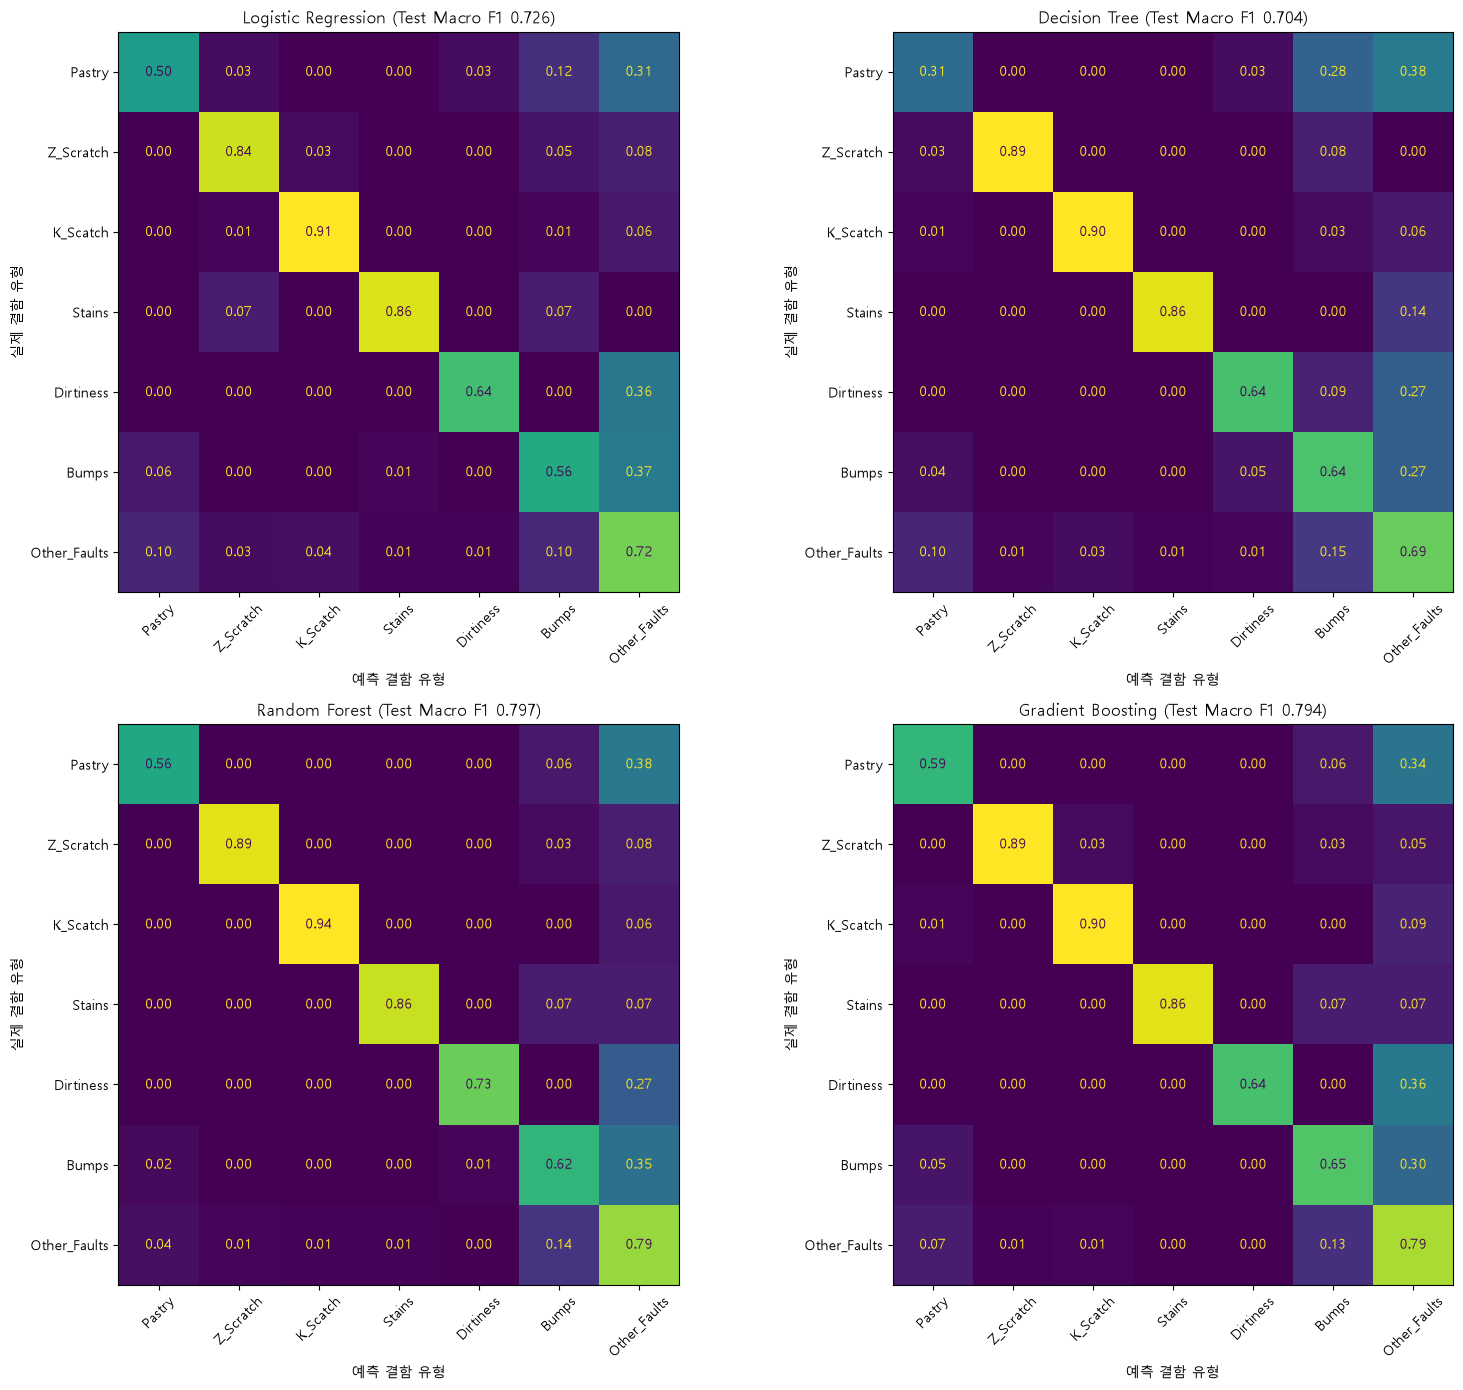

[모델별 상위 오분류 조합 (테스트)]


,Model,실제,예측,건수
0,Logistic Regression,Bumps,Other_Faults,30
1,Logistic Regression,Other_Faults,Bumps,14
2,Logistic Regression,Other_Faults,Pastry,13
3,Decision Tree,Bumps,Other_Faults,22
4,Decision Tree,Other_Faults,Bumps,20
5,Decision Tree,Other_Faults,Pastry,13
6,Random Forest,Bumps,Other_Faults,28
7,Random Forest,Other_Faults,Bumps,19
8,Random Forest,Pastry,Other_Faults,12
9,Gradient Boosting,Bumps,Other_Faults,24


In [9]:
# ============================================================
# 8. 혼동행렬 (테스트, 실제 유형 기준 비율)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, (name, pipe) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pipe.predict(X_test), labels=FAULT_COLS, normalize="true"),
        display_labels=FAULT_COLS,
    ).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
    ax.set_title(f"{name} (Test Macro F1 {test_df.loc[name, 'Macro F1']:.3f})")
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

# 모델별 가장 많은 오분류 조합
mis_rows = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    pairs = pd.Series(list(zip(y_test, pred)))[y_test != pred].value_counts().head(3)
    for (a, b), c in pairs.items():
        mis_rows.append({"Model": name, "실제": a, "예측": b, "건수": c})
print("[모델별 상위 오분류 조합 (테스트)]")
display(pd.DataFrame(mis_rows))

In [10]:
# ============================================================
# 9. 결과 저장 (이후 실험과 비교용)
# ============================================================
# 이후 실험 노트북에서 split_indices.joblib 로 같은 분할을 불러오고,
# 아래 CSV와 같은 형식으로 결과를 만들어 Experiment 열로 이어 붙이면
# Baseline 대비 Macro F1 변화량과 등급별 변화를 바로 비교할 수 있다.
# ============================================================

scores_df.insert(0, "Experiment", "Baseline")
per_class_df.insert(0, "Experiment", "Baseline")
scores_df.to_csv("baseline_scores.csv", index=False, encoding="utf-8-sig")
per_class_df.to_csv("baseline_per_class_test.csv", index=False, encoding="utf-8-sig")
print("저장 완료: baseline_scores.csv, baseline_per_class_test.csv, split_indices.joblib")

print("\n[요약] Baseline Val / Test Macro F1")
display(f1_table[["Val", "Test"]].sort_values("Val", ascending=False).round(4))

저장 완료: baseline_scores.csv, baseline_per_class_test.csv, split_indices.joblib

[요약] Baseline Val / Test Macro F1


Split,Val,Test
Model,,
Gradient Boosting,0.7865,0.7941
Random Forest,0.7842,0.7967
Logistic Regression,0.7292,0.7258
Decision Tree,0.7081,0.7036
